# Python · Kriging — robustness: degenerate and adversarial inputs

**Idea.** What happens off the happy path: invalid, degenerate or ill-conditioned
inputs must be rejected or handled, results must not depend on the units, and the
prediction cost must grow linearly with the number of points.

**Reference.** Equivariance identities (rescaled inputs / outputs give rescaled
results) and the O(q) cost of `predict`.

**Tags.** class: Kriging · topic: robustness, invariance, cost

What a user eventually feeds a surrogate model, and what must happen:

| input | expected behaviour |
|---|---|
| NaN / Inf in X or y | rejected with an exception (never a silent NaN model) |
| X and y with inconsistent sizes | rejected |
| a wrong number of warping specs | rejected |
| duplicated design points, noise-free | either rejected or a finite model (no NaN, no crash) |
| duplicated design points with `noise="nugget"` | a finite model |
| constant response y | a finite model predicting the constant |
| very few points (n = 2, 3) | a finite model |
| very clustered points (1e-8 apart) with the `gauss` kernel | finite predictions (ill-conditioning) |
| inputs scaled by 1e6 or 1e-6 with `normalize=True` | the same predictions as on [0,1] |
| y scaled by 1e8 / shifted by 1e6 | predictions scaled / shifted accordingly (equivariance) |
| predicting far outside the design | the mean reverts to the trend, the stdev to (slightly above) √σ² |
| many prediction points | cost linear in their number (mean and stdev only need O(n·q), not O(q²)) |

In [1]:
# Setup for running this notebook outside the repository (Colab, Binder, a lone copy):
# nothing to do in the repository itself (CI, local runs). Otherwise the repository
# (datasets of data/, helpers of tools/python/gallery.py) is cloned and the released pylibkriging installed.
import importlib
import os
import subprocess
import sys
from pathlib import Path

if not Path("tools/known_issues.csv").is_file():
    if not Path("gallery/tools/known_issues.csv").is_file():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/libKriging/gallery"], check=True)
    os.chdir("gallery")
    try:
        import pylibkriging  # noqa: F401
    except ImportError:
        r = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "pylibkriging"],
                           capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(
                f"pylibkriging could not be installed for Python {sys.version_info.major}.{sys.version_info.minor} "
                "(PyPI has wheels for CPython 3.10 to 3.12 only). On Colab: Runtime > Change runtime version > "
                "2026.07 (Python 3.12), then run again.\n" + r.stderr[-500:])
        importlib.invalidate_caches()
sys.path.insert(0, str(Path("tools/python").resolve()))  # for "import gallery" (tools/python/gallery.py)
print("working directory:", os.getcwd())

working directory: /home/runner/work/gallery/gallery


In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pylibkriging as lk

import gallery
from gallery import TESTS, design, compat

suite = gallery.Suite("robustness-invalid-inputs_Kriging_python")
print("pylibkriging", compat.version())
tf = TESTS["branin"]
X, y, Xt, yt = design.dataset(tf, 20, n_test=200, seed=71)


def pred(k, Xn):
    m, s, *_ = k.predict(Xn, return_stdev=True)
    return np.ravel(m), np.ravel(s)


def finite_model(check, make, Xn=Xt, severity="error"):
    """The model either raises (acceptable) or predicts finite values."""
    try:
        k = make()
    except Exception as exc:  # noqa: BLE001
        suite.check_true(f"{check}: rejected or finite", True, detail=f"rejected: {type(exc).__name__}")
        return None
    m, s = pred(k, Xn)
    suite.check_true(f"{check}: rejected or finite", np.all(np.isfinite(m)) and np.all(np.isfinite(s)),
               detail=f"non-finite: {np.sum(~np.isfinite(m))} mean, {np.sum(~np.isfinite(s))} stdev",
               severity=severity)
    return k

pylibkriging 1.2.2


## Invalid inputs are rejected

In [3]:
Xn = X.copy(); Xn[3, 1] = np.nan
yn = y.copy(); yn[5] = np.nan
yi = y.copy(); yi[5] = np.inf
suite.check_raises("NaN in X is rejected", lambda: lk.Kriging(y, Xn, "matern5_2"))
suite.check_raises("NaN in y is rejected", lambda: lk.Kriging(yn, X, "matern5_2"))
suite.check_raises("Inf in y is rejected", lambda: lk.Kriging(yi, X, "matern5_2"))
suite.check_raises("len(y) != nrow(X) is rejected", lambda: lk.Kriging(y[:-1], X, "matern5_2"))
suite.check_raises("unknown kernel is rejected", lambda: lk.Kriging(y, X, "matern7_2"))
suite.check_raises("unknown trend is rejected", lambda: lk.Kriging(y, X, "matern5_2", regmodel="cubic"))
suite.check_raises("unknown objective is rejected", lambda: lk.Kriging(y, X, "matern5_2", objective="XYZ"))
suite.check_raises("noise vector of the wrong length is rejected",
             lambda: lk.Kriging(y, X, "matern5_2", noise=np.ones(len(y) - 1)))
suite.check_raises("negative noise variance is rejected",
             lambda: lk.Kriging(y, X, "matern5_2", noise=-np.ones(len(y))), severity="warn")
k = lk.Kriging(y, X, "matern5_2")
suite.check_raises("predict with the wrong number of columns is rejected", lambda: k.predict(np.ones((3, 3)), True))
if compat.has("WarpKriging"):
    suite.check_raises("WarpKriging with 1 spec for 2 columns is rejected", lambda: lk.WarpKriging(y, X, ["none"], "gauss"))
    suite.check_raises("WarpKriging with an unknown spec is rejected",
                 lambda: lk.WarpKriging(y, X, ["none", "spline"], "gauss"))

[KNOWN] NaN in y is rejected: value=no exception expected an exception Kriging accepts NaN in y without raising
[KNOWN] Inf in y is rejected: value=no exception expected an exception Kriging accepts Inf in y without raising


[KNOWN] WarpKriging with 1 spec for 2 columns is rejected: value=no exception expected an exception WarpKriging accepts fewer warping specs than columns of X


## Degenerate designs and responses

In [4]:
Xd = np.vstack([X, X[:3]]); yd = np.concatenate([y, y[:3]])
finite_model("duplicated points, noise-free", lambda: lk.Kriging(yd, Xd, "matern5_2"))
if compat.has("noise"):
    k = finite_model("duplicated points, nugget", lambda: lk.Kriging(yd, Xd, "matern5_2", noise="nugget"))
    suite.check_true("duplicated points, nugget: a model is built", k is not None)
kc = finite_model("constant y", lambda: lk.Kriging(np.full(20, 3.7), X, "matern5_2"))
if kc is not None:
    suite.check_close("constant y: predicts the constant", pred(kc, Xt)[0], np.full(len(Xt), 3.7), rtol=1e-6, atol=1e-6)
for n in (2, 3):
    finite_model(f"n = {n}", lambda: lk.Kriging(y[:n], X[:n], "matern5_2"))
Xclose = np.vstack([X[:10], X[:10] + 1e-8])
yclose = tf.unit(Xclose)
for kernel in ("gauss", "matern5_2"):
    finite_model(f"points 1e-8 apart, {kernel}", lambda: lk.Kriging(yclose, Xclose, kernel))
# a single input dimension constant over the design
Xconst = np.column_stack([X[:, 0], np.full(20, 0.5)])
finite_model("one input constant over the design", lambda: lk.Kriging(tf.unit(Xconst), Xconst, "matern5_2"))

## Scale invariance and equivariance

In [5]:
k0 = lk.Kriging(y, X, "matern5_2", normalize=True)
m0, s0 = pred(k0, Xt)
for scale in (1e-6, 1e6):
    with suite.check_runs(f"X * {scale:g} with normalize=True: fit"):
        ks = lk.Kriging(y, X * scale, "matern5_2", normalize=True)
        suite.check_close(f"X * {scale:g}, normalize=True: same mean as on [0,1]", pred(ks, Xt * scale)[0], m0,
                    rtol=1e-3, atol=1e-3 * np.std(y))
for a, b in [(1e8, 0.0), (1.0, 1e6), (1e-8, 0.0)]:
    with suite.check_runs(f"y * {a:g} + {b:g}: fit"):
        ka = lk.Kriging(a * y + b, X, "matern5_2", normalize=True)
        ma, sa = pred(ka, Xt)
        suite.check_close(f"y * {a:g} + {b:g}: mean equivariant", ma, a * m0 + b, rtol=1e-3, atol=1e-3 * a * np.std(y))
        suite.check_close(f"y * {a:g} + {b:g}: stdev scales by |a|", sa, abs(a) * s0, rtol=1e-2,
                    atol=1e-3 * a * np.std(y))
# the same without normalize: the optimizer starts from a scale-dependent point, warn-level only
for a, b in [(1e6, 0.0), (1.0, 1e6)]:
    ka = lk.Kriging(a * y + b, X, "matern5_2")
    suite.check_close(f"y * {a:g} + {b:g} (normalize=False): mean equivariant", pred(ka, Xt)[0],
                a * pred(lk.Kriging(y, X, "matern5_2"), Xt)[0] + b, rtol=1e-3, atol=1e-3 * a * np.std(y),
                severity="warn")

## Far from the data

In [6]:
k = lk.Kriging(y, X, "matern5_2")
far = np.array([[50.0, 50.0], [-30.0, 80.0]])
m, s = pred(k, far)
suite.check_close("far away: mean -> beta (constant trend)", m, np.full(2, np.ravel(k.beta())[0]), rtol=1e-6,
            atol=1e-8)
# universal kriging: sigma2 * (1 + 1 / (1' R^-1 1)) with the trend uncertainty, slightly above sigma2
suite.check_between("far away: stdev / sqrt(sigma2)", np.max(s) / np.sqrt(k.sigma2()), 1.0 - 1e-6, 1.5)
suite.check_close("far away: same stdev at both points", s[0], s[1], rtol=1e-6)

True

## Many prediction points

Mean and stdev at q points need O(n·q) operations and memory; only the full
covariance (`return_cov=True`) is O(q²). The time for q = 1000, 2000, 4000,
8000 points must grow linearly (log2 of the ratio per doubling ~ 1). An
exponent close to 2 means a q × q matrix is formed: a million points then needs
terabytes. (Not run at 10⁶ points directly: it would exhaust the runner.)

[KNOWN] predict(stdev) time growth exponent in q (8000 vs 4000): value=1.84826 expected < 1.5 predict(return_stdev=True, return_cov=False) is O(q^2) in time and memory (10 000 points: 1.6 GB; 30 000: out of memory) | q=1000: 0.004s, q=2000: 0.010s, q=4000: 0.030s, q=8000: 0.108s


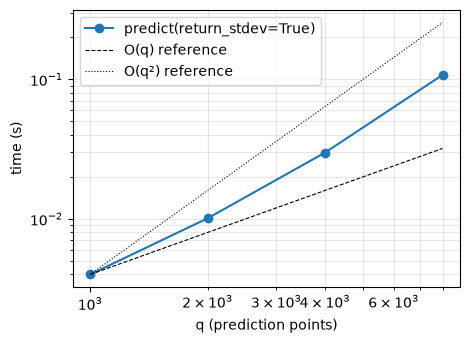

In [7]:
times = {}
for q in (1000, 2000, 4000, 8000):
    Xq = design.uniform(q, 2, seed=72)
    best = np.inf
    for _ in range(3):
        t0 = time.perf_counter()
        pred(k, Xq)
        best = min(best, time.perf_counter() - t0)
    times[q] = best
    suite.metric(f"predict_q={q}", "pylibkriging", seconds=best)
expo = np.log2(times[8000] / times[4000])
suite.check_less("predict(stdev) time growth exponent in q (8000 vs 4000)", expo, 1.5,
           detail=", ".join(f"q={q}: {t:.3f}s" for q, t in times.items()))
qs = np.array(list(times)); ts = np.array(list(times.values()))
plt.figure(figsize=(5, 3.6))
plt.loglog(qs, ts, "o-", label="predict(return_stdev=True)")
plt.loglog(qs, ts[0] * qs / qs[0], "k--", lw=.8, label="O(q) reference")
plt.loglog(qs, ts[0] * (qs / qs[0]) ** 2, "k:", lw=.8, label="O(q²) reference")
plt.xlabel("q (prediction points)"); plt.ylabel("time (s)"); plt.legend(); plt.grid(True, which="both", alpha=.3)
plt.show()

## Summary

The metrics of this notebook, the number of checks per status, and every check that
did not pass (FAIL: error-level, fails the run; WARN: warn-level; KNOWN: listed in
`tools/known_issues.csv`, with its issue; SKIP: feature absent from the installed version).
All of them are also written to `results/robustness-invalid-inputs_Kriging_python.checks.csv` and `.metrics.csv`.

In [8]:
suite.summary()

,metric,seconds
case,package,
predict_q=1000,pylibkriging,0.0040
predict_q=2000,pylibkriging,0.0101
predict_q=4000,pylibkriging,0.0299
predict_q=8000,pylibkriging,0.1075


41 checks: PASS 37, FAIL 0, WARN 0, KNOWN 4, SKIP 0


,status,severity,check,value,expected,detail
0,KNOWN,error,NaN in y is rejected,no exception,an exception,Kriging accepts NaN in y without raising
1,KNOWN,error,Inf in y is rejected,no exception,an exception,Kriging accepts Inf in y without raising
2,KNOWN,error,WarpKriging with 1 spec for 2 columns is rejected,no exception,an exception,WarpKriging accepts fewer warping specs than c...
3,KNOWN,error,predict(stdev) time growth exponent in q (8000...,1.84826,< 1.5,"predict(return_stdev=True, return_cov=False) i..."


In [9]:
suite.finalize()

robustness-invalid-inputs_Kriging_python: PASS 37, FAIL 0, WARN 0, KNOWN 4, SKIP 0


{'PASS': 37, 'FAIL': 0, 'WARN': 0, 'KNOWN': 4, 'SKIP': 0}